# QA-Faktenretention bei vergleichbarer tatsächlicher Wortzahl

## Eingaben und Ausgaben

Nach der einmaligen Vorbereitung mit `python 05_analyze.py --prepare` genügt **Run All**.
Die folgende Zelle zeigt Daten, Vorgängertabellen und neue Ausgaben. `DATA_DIR` und
`OUTPUT_DIR` dürfen auf eigene absolute Verzeichnisse zeigen. `TABLES` liest standardmäßig
die vorbereiteten historischen Tabellen; für selbst neu erzeugte Vorgängertabellen
kann hier `OUTPUT_DIR / "tables"` stehen. Eingaben und neue Ausgaben bleiben getrennt.


In [1]:
from pathlib import Path
from faktenretention.paths import PROJECT_ROOT
from faktenretention.notebook_context import setup_notebook
from faktenretention.io import relative_path, sha

# Hier können eigene absolute Daten- und Ausgabeverzeichnisse stehen.
DATA_DIR = PROJECT_ROOT / "data/prepared"
OUTPUT_DIR = PROJECT_ROOT / "results/notebooks"
# Historische Vorgängertabellen; für eigene Neuberechnungen OUTPUT_DIR / "tables" einsetzen.
TABLES = DATA_DIR / "tables"
setup_notebook(DATA_DIR, OUTPUT_DIR)
OUT = OUTPUT_DIR / "tables/07_laengenmatched_matrizen"
FIG = OUTPUT_DIR / "figures/07_laengenmatched_matrizen"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
print("Eingaben:", DATA_DIR / "qa")
print("Vorgängertabellen:", TABLES)
print("Neue Tabellen:", OUT)
print("Neue Grafiken:", FIG)
from faktenretention.notebook_context import display_figure


Eingaben: /home/edgar/Faktenretention_Notebook_Refactor/data/prepared/qa
Vorgängertabellen: /home/edgar/Faktenretention_Notebook_Refactor/data/prepared/tables
Neue Tabellen: /home/edgar/Faktenretention_Notebook_Refactor/results/notebooks/tables/07_laengenmatched_matrizen
Neue Grafiken: /home/edgar/Faktenretention_Notebook_Refactor/results/notebooks/figures/07_laengenmatched_matrizen


Vier separate Vergleichsmatrizen für **500, 300, 150 und 75 Zielwörter**.
Verfahren: Lead-k, Plain, Zero-Shot-CoT, Few-Shot-CoT, Auto-CoT und Automate-CoT.
Datenstand: **aktuell_20260930**, die im Quellenmanifest ausgewiesene Standardversion.

## Kontext und Methoden

Verglichen werden ausschließlich zwei Ausgaben **desselben Artikels auf derselben Zielstufe**.
Die Auswahl erfolgt ausschließlich anhand der tatsächlichen Wortzahlen:

\[
\frac{|W_A-W_B|}{(W_A+W_B)/2}\leq 0{,}05,\qquad (W_A+W_B)/2>0.
\]

Wortzählung wie im Hauptexperiment: `re.findall(r"\b\w+\b", text)`.
Bei ganzzahligen Wortzahlen ist die Auswahlregel exakt äquivalent zu
`40 * abs(W_A - W_B) <= W_A + W_B`; es gibt keine Rundung an der 5-%-Grenze.
Ein leerer Text ist durch diese Regel automatisch nicht mit einem nichtleeren Text vergleichbar;
zwei leere Texte werden wegen der mittleren Wortzahl null ausgeschlossen.

Retention ist die beobachtete Quote **R = n_retained / n_valid**, ohne Längenabschlag.
Technisch fehlende QA-Urteile zählen nicht zum Nenner. Beide Ausgaben müssen einen positiven
gültigen QA-Nenner und eine endliche beobachtete Retention besitzen.
Diese Verfügbarkeit wird erst nach der wortzahlbasierten Auswahl geprüft; Retentionswerte
beeinflussen weder die Längenauswahl noch die Zusammenstellung der Stichprobe.
Teilweise fehlende QA ist bei positivem Nenner zulässig.

Jede Zelle zeigt den gleichgewichteten Artikelmittelwert von
**ΔR = 100 × (R_Zeile − R_Spalte)** in Prozentpunkten und die Anzahl **n** vollständiger Artikelpaare.
Positive Werte bedeuten höhere Retention des Zeilenverfahrens, negative höhere Retention
des Spaltenverfahrens. Diagonalen bleiben leer; grau mit „kein Vergleich“ bedeutet n = 0.
Alle vier Matrizen verwenden dieselbe symmetrische divergierende Farbskala um null.
**† und ein gestrichelter Rahmen kennzeichnen 0 < n < 10**: Hinweis auf die kleine
Stichprobe, keine feste Grenze statistischer Belastbarkeit und keine Signifikanzmarkierung.

Die begleitenden Tabellen zeigen **punktweise 95-%-Perzentilintervalle** aus
**10.000 Bootstrap-Ziehungen vollständiger Artikelpaare mit Zurücklegen**, je Vergleich
mit dessen n Paaren und fester Längenauswahl. Beide Verfahren eines Artikels bleiben
in jeder Ziehung zusammen. Seed 32, deterministischer Teilstrom je Zielstufe und
ungeordnetem Methodenpaar; Quantile 2,5 % und 97,5 %, lineare Interpolation.
Für n < 2 wird kein Intervall berechnet. Die Intervalle sind **nicht für multiple
Vergleiche korrigiert**. Die Tabellen enthalten 15 eindeutige Paare je Zielstufe;
umgekehrte Vergleiche haben den negierten Mittelwert und das Intervall [−Obergrenze, −Untergrenze].

### Annahmen und Grenzen

Die Verfahren können je Paar auf unterschiedlichen Artikelmengen verglichen werden.
Die Matrizen begründen daher keine einheitliche Methodenrangfolge oder Kausalwirkung.
Die Bootstrap-Intervalle gelten für die jeweiligen ausgewählten Paare, nicht für alle
100 Artikel oder die Unsicherheit einer neu durchgeführten Auswahl.

## Daten und Reproduzierbarkeit

Die eingefrorenen Zusammenfassungstexte und 48.000 archivierten QA-Einzelbewertungen
werden über ihr Quellenmanifest geprüft. Retention wird aus den QA-Zählern neu berechnet
und gegen den bestehenden Artikel- und Längenexport abgeglichen.
Das Notebook schreibt nur in seine eigenen Ergebnis- und Grafikordner.
Benötigt: Python, numpy, pandas, matplotlib, nbformat, nbclient, nbconvert und ipykernel.
Keine Modell- oder Netzwerkaufrufe.

In [2]:
from pathlib import Path
from itertools import combinations
import hashlib, importlib.metadata, json, math, platform, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.patches import Rectangle
from IPython.display import display, Markdown

BASE = DATA_DIR
VERSION, SEED, B = "aktuell_20260930", 32, 10_000
from faktenretention.protocol import METHODS
from faktenretention.protocol import LABELS as NAMES
from faktenretention.protocol import STAGES
KEY = ["article_id", "method", "stage_target_words"]
DATA = DATA_DIR / "qa"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
sources = []
manifest_path = DATA/"source_manifest.json"
source_manifest = json.loads(manifest_path.read_text())
assert source_manifest["default_version"] == VERSION

def record_source(path, role, expected=None):
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    if expected is not None:
        assert digest == expected, f"Quellenhash verändert: {path}"
    sources.append({"Datei":relative_path(path, BASE), "SHA256":digest, "Rolle":role})

def frozen_input(relative):
    entry = next(e for e in source_manifest["files"] if e["file"] == relative)
    path = DATA/relative
    record_source(path, "eingefrorene Eingabe", entry["sha256"])
    return path

from faktenretention.io import read_table as read

def as_bool(series):
    values = series.astype(str).str.lower()
    assert values.isin(["true", "false"]).all()
    return values.eq("true")

record_source(manifest_path, "Quellenmanifest")
summaries = read(frozen_input(VERSION+"/summaries.csv.gz"))
scored = read(frozen_input(VERSION+"/scored_archived.csv.gz")).rename(columns={"summary_prompt_variant":"method"})
archived = read(frozen_input(VERSION+"/article_archived.csv.gz"))
qa_path = TABLES / "03_qa_retention"/"retention_artikelebene.csv"
length_path = TABLES / "04_laenge_und_adjustierte_retention"/"artikelwerte_laenge_retention.csv"
record_source(qa_path, "Artikelretention zum unabhängigen Exportabgleich")
record_source(length_path, "Wortzähler und Retention zum Exportabgleich")
qa_check, length_check = read(qa_path), read(length_path)
IDS = sorted(summaries.article_id.unique())
assert len(IDS) == 100 and len(summaries) == 600
assert not summaries.duplicated(["article_id", "method"]).any()
assert set(summaries[["article_id","method"]].itertuples(index=False, name=None)) == {(a,m) for a in IDS for m in METHODS}
expected_phase = {m:"plain_fewshot_rerun_20260930" if m in ["plain","few_shot_cot"]
                  else "final_100_frozen_temperature_0" for m in METHODS}
assert summaries.collection_phase.eq(summaries.method.map(expected_phase)).all()
assert len(scored) == 48_000
assert not scored.duplicated(KEY+["canonical_fact_id"]).any()
assert scored.groupby(KEY).size().eq(20).all()
scored["valid"] = as_bool(scored.analysis_eligible)
assert scored.valid.eq(~as_bool(scored.technical_missing)).all()
scored["retained_valid"] = scored.valid & scored.retention.astype(str).str.lower().eq("true")
counts = scored.groupby(KEY).agg(n_valid=("valid","sum"), n_retained=("retained_valid","sum")).reset_index()
counts["R"] = counts.n_retained/counts.n_valid.replace(0, np.nan)
rows = []


In [3]:
from faktenretention.text_rules import count_words
for target in STAGES:
    current = summaries[["article_id", "method", f"summary_{target}", f"summary_{target}_word_count"]].copy()
    current.columns = ["article_id", "method", "summary", "W_stored"]
    current["stage_target_words"] = target
    current["W"] = current.summary.map(count_words)
    assert current.W.eq(current.W_stored.astype(int)).all()
    rows.append(current[KEY+["W"]])
article_values = pd.concat(rows, ignore_index=True).merge(counts, on=KEY, validate="one_to_one")
assert len(article_values) == 2400 and not article_values.duplicated(KEY).any()
assert set(article_values[KEY].itertuples(index=False, name=None)) == {(a,m,t) for a in IDS for m in METHODS for t in STAGES}
assert article_values.W.ge(0).all()
for external, n_col, r_col, k_col, w_col in [
    (qa_check, "n_valid", "retention_observed", "n_retained", None),
    (length_check, "V", "R_obs", "K", "W"),
    (archived, "n_analyzed", "retention", None, None),
]:
    external = external.set_index(KEY).reindex(pd.MultiIndex.from_frame(article_values[KEY]))
    assert np.array_equal(article_values.n_valid.to_numpy(), external[n_col].to_numpy(dtype=int))
    assert np.allclose(article_values.R, pd.to_numeric(external[r_col], errors="coerce"), atol=1e-14, rtol=0, equal_nan=True)
    if k_col:
        assert np.array_equal(article_values.n_retained.to_numpy(), external[k_col].to_numpy(dtype=int))
    if w_col:
        assert np.array_equal(article_values.W.to_numpy(), external[w_col].to_numpy(dtype=int))
article_values.to_csv(OUT/"artikelwerte_wortzahl_retention.csv", index=False)
pd.DataFrame(sources).to_csv(OUT/"quellen_sha256.csv", index=False)
display(Markdown(f"**Geprüft:** {len(IDS)} Artikel, {len(article_values):,} Ausgaben und {len(scored):,} QA-Positionen. Alle Wortzähler und Retentionswerte stimmen mit den bestehenden Exporten überein."))
display(article_values.head(6).rename(columns={"W":"Wortzahl", "R":"Retention"}))


**Geprüft:** 100 Artikel, 2,400 Ausgaben und 48,000 QA-Positionen. Alle Wortzähler und Retentionswerte stimmen mit den bestehenden Exporten überein.

,article_id,method,stage_target_words,Wortzahl,n_valid,n_retained,Retention
0,1,lead_k,500,500,20,13,0.650000
1,1,zero_shot_cot,500,432,20,10,0.500000
2,1,auto_cot,500,343,20,13,0.650000
3,1,automate_cot,500,435,19,14,0.736842
4,2,lead_k,500,500,20,17,0.850000
5,2,zero_shot_cot,500,409,20,17,0.850000


## Paarbildung und Bootstrap

Zuerst die exakte Wortzahlregel anwenden, anschließend vollständige auswertbare Paare bilden. Kein Filter auf die Höhe der Retention.

In [4]:
pair_results, audit_parts, boot_distributions = [], [], {}
for target in STAGES:
    stage_data = article_values[article_values.stage_target_words.eq(target)]
    for i, j in combinations(range(len(METHODS)), 2):
        method_a, method_b = METHODS[i], METHODS[j]
        left = stage_data[stage_data.method.eq(method_a)][["article_id", "W", "R", "n_valid", "n_retained"]]
        right = stage_data[stage_data.method.eq(method_b)][["article_id", "W", "R", "n_valid", "n_retained"]]
        pairs = left.merge(right, on="article_id", suffixes=("_row", "_column"), validate="one_to_one").sort_values("article_id")
        assert len(pairs) == len(IDS)
        total_words = pairs.W_row+pairs.W_column
        word_difference = (pairs.W_row-pairs.W_column).abs()
        pairs["mean_word_count"] = total_words/2
        pairs["relative_word_difference"] = 2*word_difference/total_words.replace(0, np.nan)
        pairs["length_eligible"] = total_words.gt(0) & (40*word_difference).le(total_words)
        pairs["qa_available"] = (pairs.n_valid_row.gt(0) & pairs.n_valid_column.gt(0)
                                 & np.isfinite(pairs.R_row) & np.isfinite(pairs.R_column))
        pairs["included"] = pairs.length_eligible & pairs.qa_available
        pairs["delta_pp"] = 100*(pairs.R_row-pairs.R_column)
        pairs["stage_target_words"] = target
        pairs["row_method"], pairs["column_method"] = method_a, method_b
        pairs["exclusion_reason"] = np.select(
            [total_words.eq(0), ~pairs.length_eligible, ~pairs.qa_available],
            ["mittlere Wortzahl null", "Wortzahldifferenz über 5 %", "ungültiger QA-Nenner oder fehlende Retention"],
            default="berücksichtigt")
        audit_parts.append(pairs)
        selected = pairs.loc[pairs.included, "delta_pp"].to_numpy(dtype=float)
        n = len(selected)
        mean = float(selected.mean()) if n else np.nan
        lo = hi = np.nan
        if n >= 2:
            rng = np.random.default_rng(np.random.SeedSequence([SEED, target, i, j]))
            indices = rng.integers(0, n, size=(B, n))
            boot_means = selected[indices].mean(axis=1)
            lo, hi = np.quantile(boot_means, [.025, .975], method="linear")
            boot_distributions[f"stage{target}_pair{i}_{j}"] = boot_means
        pair_results.append({"stage_target_words":target, "row_method":method_a, "column_method":method_b,
                             "mean_delta_pp":mean, "n":n, "ci95_low_pp":lo, "ci95_high_pp":hi,
                             "small_sample":0 < n < 10, "n_length_eligible":int(pairs.length_eligible.sum()),
                             "n_qa_unavailable_after_length":int((pairs.length_eligible & ~pairs.qa_available).sum()),
                             "n_zero_mean_words":int(total_words.eq(0).sum())})
comparisons = pd.DataFrame(pair_results)
pair_audit = pd.concat(audit_parts, ignore_index=True)
assert len(comparisons) == 60 and len(pair_audit) == 6000
mirrored = comparisons.copy()
mirrored["row_method"], mirrored["column_method"] = comparisons.column_method, comparisons.row_method
mirrored["mean_delta_pp"] = -comparisons.mean_delta_pp
mirrored["ci95_low_pp"], mirrored["ci95_high_pp"] = -comparisons.ci95_high_pp, -comparisons.ci95_low_pp
matrix_cells = pd.concat([comparisons, mirrored], ignore_index=True)
assert len(matrix_cells) == 120
comparisons.to_csv(OUT/"bootstrap_intervalle_60_eindeutige_vergleiche.csv", index=False)
matrix_cells.to_csv(OUT/"matrixzellen_120_gerichtete_vergleiche.csv", index=False)
pair_audit.to_csv(OUT/"paarbildung_audit_6000_artikelpaare.csv", index=False)
pair_audit[pair_audit.included].to_csv(OUT/"beruecksichtigte_artikelpaare.csv", index=False)
pass  # Große Bootstrap-Zwischendatei wird nicht benötigt.

maximum = matrix_cells.mean_delta_pp.abs().max()
COLOR_LIMIT = max(5, 5*math.ceil(maximum/5)) if pd.notna(maximum) else 5
CMAP = LinearSegmentedColormap.from_list("signed_retention", ["#a84921", "#fafafa", "#12568a"])
NORM = TwoSlopeNorm(vmin=-COLOR_LIMIT, vcenter=0, vmax=COLOR_LIMIT)
plt.rcParams.update({"font.family":"DejaVu Sans", "font.size":12, "axes.titlesize":18,
                     "svg.fonttype":"none", "savefig.facecolor":"white"})
summary = comparisons.groupby("stage_target_words", sort=False).agg(
    Vergleiche=("n","size"), Ohne_Vergleich=("n", lambda s: int(s.eq(0).sum())),
    Kleine_Stichprobe=("small_sample","sum"), Min_n=("n","min"), Max_n=("n","max"))
display(summary)
display(Markdown(f"**Gemeinsame Farbskala:** −{COLOR_LIMIT} bis +{COLOR_LIMIT} Prozentpunkte, Mittelpunkt null. **†**: weniger als zehn Artikelpaare; keine feste Belastbarkeitsgrenze."))


,Vergleiche,Ohne_Vergleich,Kleine_Stichprobe,Min_n,Max_n
stage_target_words,,,,,
500,15,5,5,0,29
300,15,1,4,0,29
150,15,0,5,2,20
75,15,1,6,0,23


**Gemeinsame Farbskala:** −25 bis +25 Prozentpunkte, Mittelpunkt null. **†**: weniger als zehn Artikelpaare; keine feste Belastbarkeitsgrenze.

In [5]:
def de_number(value, signed=True):
    if pd.isna(value):
        return "—"
    if abs(value) < .005:
        value = 0.0
    return (f"{value:+.2f}" if signed else f"{value:.2f}").replace(".", ",").replace("-", "−")

def draw_matrix(target, save=True):
    lookup = matrix_cells[matrix_cells.stage_target_words.eq(target)].set_index(["row_method", "column_method"])
    values = np.full((6, 6), np.nan)
    fig, ax = plt.subplots(figsize=(12.2, 10.5))
    for i, method_row in enumerate(METHODS):
        for j, method_column in enumerate(METHODS):
            if i != j:
                values[i,j] = lookup.loc[(method_row, method_column), "mean_delta_pp"]
    cmap = CMAP.copy()
    cmap.set_bad("white")
    image = ax.imshow(np.ma.masked_invalid(values), cmap=cmap, norm=NORM, interpolation="nearest")
    for i, method_row in enumerate(METHODS):
        for j, method_column in enumerate(METHODS):
            if i == j:
                continue
            row = lookup.loc[(method_row, method_column)]
            if row.n == 0:
                ax.add_patch(Rectangle((j-.5,i-.5),1,1,facecolor="#dedede",edgecolor="white",linewidth=1.5))
                ax.text(j,i,"kein\nVergleich",ha="center",va="center",fontsize=11,color="#343434")
            else:
                value = row.mean_delta_pp
                rgb = CMAP(NORM(value))[:3]
                def linear_channel(channel):
                    return channel/12.92 if channel <= .04045 else ((channel+.055)/1.055)**2.4
                luminance = sum(w*linear_channel(v) for w,v in zip([.2126,.7152,.0722],rgb))
                text_color = "white" if (luminance+.05)/.05 < 4.5 else "#171717"
                marker = " †" if row.small_sample else ""
                ax.text(j,i,f"{de_number(value)} PP\nn = {int(row.n)}{marker}",ha="center",va="center",
                        fontsize=11.5,color=text_color,linespacing=1.5)
                if row.small_sample:
                    ax.add_patch(Rectangle((j-.44,i-.44),.88,.88,fill=False,edgecolor=text_color,
                                           linewidth=1.1,linestyle=(0,(3,3))))
    ax.set_xticks(range(6), [NAMES[m] for m in METHODS], rotation=32, ha="left", rotation_mode="anchor")
    ax.set_yticks(range(6), [NAMES[m] for m in METHODS])
    ax.xaxis.tick_top()
    ax.tick_params(axis="both",which="both",length=0,pad=9,labelsize=12)
    ax.set_xticks(np.arange(-.5,6,1),minor=True)
    ax.set_yticks(np.arange(-.5,6,1),minor=True)
    ax.grid(which="minor",color="white",linewidth=1.5)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_title(f"Zielstufe {target} Wörter",loc="left",pad=108)
    fig.text(.07,.952,"QA-Faktenretention bei höchstens 5 % Wortzahldifferenz",fontsize=13,color="#333333")
    colorbar = fig.colorbar(image,ax=ax,fraction=.044,pad=.04,shrink=.95)
    colorbar.set_label("Mittlere Differenz: Zeile − Spalte (Prozentpunkte)",fontsize=12,labelpad=12)
    ticks = np.linspace(-COLOR_LIMIT,COLOR_LIMIT,5)
    colorbar.set_ticks(ticks, labels=[de_number(x, signed=False) for x in ticks])
    colorbar.outline.set_visible(False)
    fig.text(.07,.105,"Blau / positiv: Zeilenverfahren höher · Orange / negativ: Spaltenverfahren höher",fontsize=11)
    fig.text(.07,.077,"† und gestrichelter Rahmen: n < 10; Hinweis auf kleine Stichprobe, keine feste Belastbarkeitsgrenze.",fontsize=10.5)
    fig.text(.07,.052,"Grau: kein Vergleich · Diagonale leer · Retention ohne Längenabschlag · Daten: aktuell_20260930",fontsize=10.5)
    fig.subplots_adjust(left=.215,right=.9,top=.77,bottom=.16)
    if save:
        for extension in ["png","svg","pdf"]:
            fig.savefig(FIG/f"vergleichsmatrix_{target}_woerter.{extension}",dpi=180)
    return fig

def interval_table(target):
    current = comparisons[comparisons.stage_target_words.eq(target)].copy()
    shown = pd.DataFrame({
        "Zeilenverfahren":current.row_method.map(NAMES), "Spaltenverfahren":current.column_method.map(NAMES),
        "ΔR (PP)":current.mean_delta_pp.map(de_number), "n":current.n,
        "95-%-Perzentilintervall (PP)": [
            f"[{de_number(lo)}; {de_number(hi)}]" if n >= 2 else "kein Intervall (n < 2)"
            for lo,hi,n in current[["ci95_low_pp","ci95_high_pp","n"]].itertuples(index=False,name=None)],
        "Hinweis": ["kein Vergleich" if n == 0 else "† kleine Stichprobe" if n < 10 else ""
                    for n in current.n]})
    shown.to_csv(OUT/f"intervalltabelle_{target}_woerter_formatiert.csv",index=False)
    return shown.reset_index(drop=True)


## Gemeinsame Grafik: 300 und 75 Zielwörter

Die unteren Dreiecke zeigen jedes der 15 Methodenpaare genau einmal je Stufe. Die leere erste Zeile und letzte Spalte entfallen. Blau bedeutet höhere Retention des Zeilenverfahrens, Rot höhere Retention des Spaltenverfahrens; die gemeinsame Skala bleibt −25 bis +25 Prozentpunkte. Die Zellwerte behalten ihre Richtung Zeile minus Spalte. † kennzeichnet 0 < n < 10.

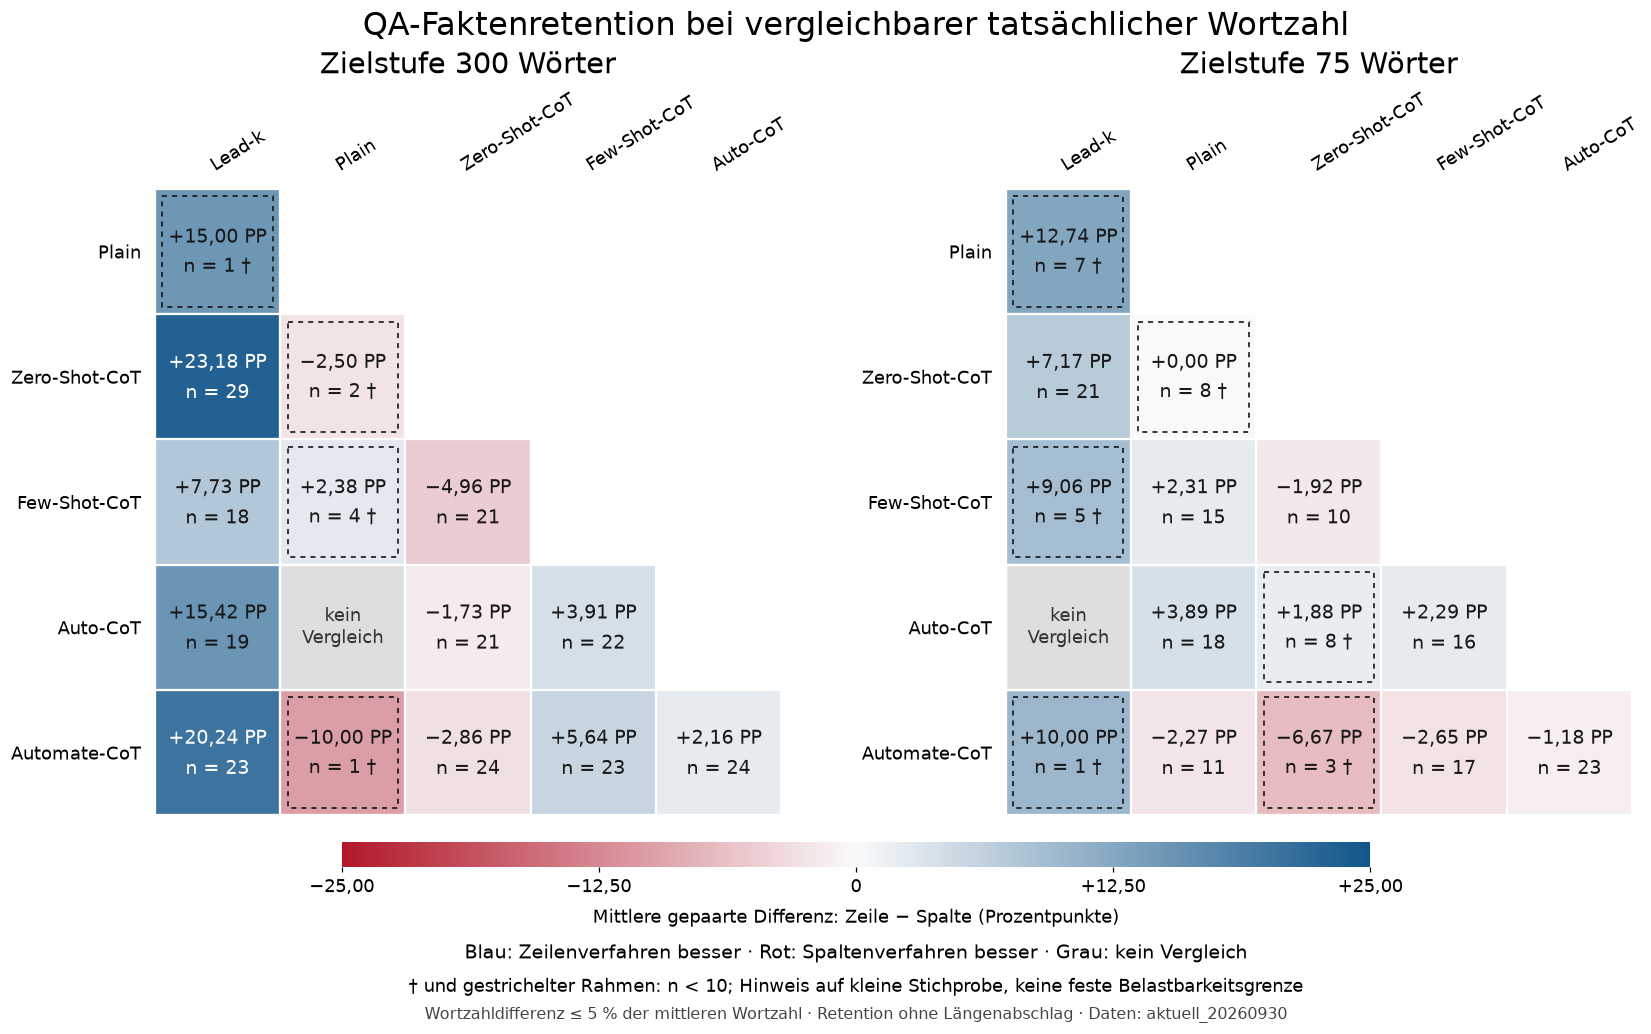

In [6]:
"""Plot the lower triangles of the reviewed 300- and 75-word matrices together."""
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.patches import Rectangle


def draw_combined_matrices(matrix_cells, color_limits, export_dir=None):
    methods = ["lead_k", "plain", "zero_shot_cot", "few_shot_cot", "auto_cot", "automate_cot"]
    names = ["Lead-k", "Plain", "Zero-Shot-CoT", "Few-Shot-CoT", "Auto-CoT", "Automate-CoT"]
    vmin, vmax = color_limits
    norm = TwoSlopeNorm(vmin=vmin, vcenter=0, vmax=vmax)
    cmap = LinearSegmentedColormap.from_list("signed_retention_red_blue", ["#b2182b", "#fafafa", "#12568a"])
    cmap.set_bad("white")
    plt.rcParams.update({"font.family":"DejaVu Sans", "font.size":12, "svg.fonttype":"none"})

    def number(value):
        if abs(value) < .005:
            value = 0.0
        return f"{value:+.2f}".replace(".", ",").replace("-", "−")

    def text_color(value):
        rgb = cmap(norm(value))[:3]
        linear = [c/12.92 if c <= .04045 else ((c+.055)/1.055)**2.4 for c in rgb]
        luminance = sum(w*c for w,c in zip([.2126,.7152,.0722],linear))
        return "white" if (luminance+.05)/.05 < 4.5 else "#171717"

    fig = plt.figure(figsize=(17,9.5), facecolor="white")
    # Remove the empty Lead-k row and Automate-CoT column along with the upper triangle.
    # The remaining ticks retain the original row/column identity and difference sign.
    for target, left in [(300,.125),(75,.58)]:
        width, bottom, height = .335, .21, .335*17/9.5
        ax = fig.add_axes([left,bottom,width,height])
        stage = matrix_cells[matrix_cells.stage_target_words.eq(target)].set_index(["row_method","column_method"])
        assert len(stage) == 30 and not stage.index.duplicated().any()
        values = np.full((5,5),np.nan)
        shown_pairs = []
        for i,row_method in enumerate(methods[1:]):
            for j,column_method in enumerate(methods[:-1]):
                if j <= i:
                    row = stage.loc[(row_method,column_method)]
                    values[i,j] = row.mean_delta_pp
                    shown_pairs.append(frozenset([row_method,column_method]))
        assert len(shown_pairs) == len(set(shown_pairs)) == 15
        image = ax.imshow(np.ma.masked_invalid(values),cmap=cmap,norm=norm,interpolation="nearest")
        for i,row_method in enumerate(methods[1:]):
            for j,column_method in enumerate(methods[:-1]):
                if j > i:
                    continue
                row = stage.loc[(row_method,column_method)]
                if row.n == 0:
                    ax.add_patch(Rectangle((j-.5,i-.5),1,1,facecolor="#dedede",edgecolor="white",linewidth=1.5))
                    ax.text(j,i,"kein\nVergleich",ha="center",va="center",fontsize=12,color="#343434")
                    continue
                color = text_color(row.mean_delta_pp)
                small = 0 < row.n < 10
                marker = " †" if small else ""
                ax.text(j,i,f"{number(row.mean_delta_pp)} PP\nn = {int(row.n)}{marker}",
                        ha="center",va="center",fontsize=12.5,color=color,linespacing=1.5)
                if small:
                    ax.add_patch(Rectangle((j-.44,i-.44),.88,.88,fill=False,edgecolor=color,
                                           linewidth=1.1,linestyle=(0,(3,3))))
        ax.set_xticks(range(5),names[:-1],rotation=32,ha="left",rotation_mode="anchor")
        ax.set_yticks(range(5),names[1:])
        ax.xaxis.tick_top()
        ax.tick_params(axis="both",which="both",length=0,pad=9,labelsize=12)
        ax.set_xticks(np.arange(-.5,5,1),minor=True)
        ax.set_yticks(np.arange(-.5,5,1),minor=True)
        ax.grid(which="minor",color="white",linewidth=1.5)
        for spine in ax.spines.values():
            spine.set_visible(False)
        fig.text(left+width/2,.92,f"Zielstufe {target} Wörter",ha="center",fontsize=19)

    fig.suptitle("QA-Faktenretention bei vergleichbarer tatsächlicher Wortzahl",x=.5,y=.98,fontsize=21)
    cax = fig.add_axes([.225,.16,.55,.024])
    colorbar = fig.colorbar(image,cax=cax,orientation="horizontal")
    ticks = np.linspace(vmin,vmax,5)
    colorbar.set_ticks(ticks,labels=[number(x) if x else "0" for x in ticks])
    colorbar.set_label("Mittlere gepaarte Differenz: Zeile − Spalte (Prozentpunkte)",fontsize=12,labelpad=8)
    colorbar.outline.set_visible(False)
    fig.text(.5,.073,"Blau: Zeilenverfahren besser · Rot: Spaltenverfahren besser · Grau: kein Vergleich",ha="center",fontsize=12.5)
    fig.text(.5,.041,"† und gestrichelter Rahmen: n < 10; Hinweis auf kleine Stichprobe, keine feste Belastbarkeitsgrenze",ha="center",fontsize=11.5)
    fig.text(.5,.015,"Wortzahldifferenz ≤ 5 % der mittleren Wortzahl · Retention ohne Längenabschlag · Daten: aktuell_20260930",ha="center",fontsize=10.5,color="#444444")
    if export_dir is not None:
        for extension in ["png","svg","pdf"]:
            path = Path(export_dir)/f"vergleichsmatrizen_300_75_woerter.{extension}"
            fig.savefig(path,dpi=220,facecolor="white")
    return fig


combined_figure = draw_combined_matrices(matrix_cells, (-COLOR_LIMIT, COLOR_LIMIT), FIG)
display_figure(combined_figure)
plt.close(combined_figure)


## Vergleichsmatrix: 500 Zielwörter

Mittlere gepaarte Differenz in Prozentpunkten und n; dieselbe Farbskala wie auf allen anderen Stufen.

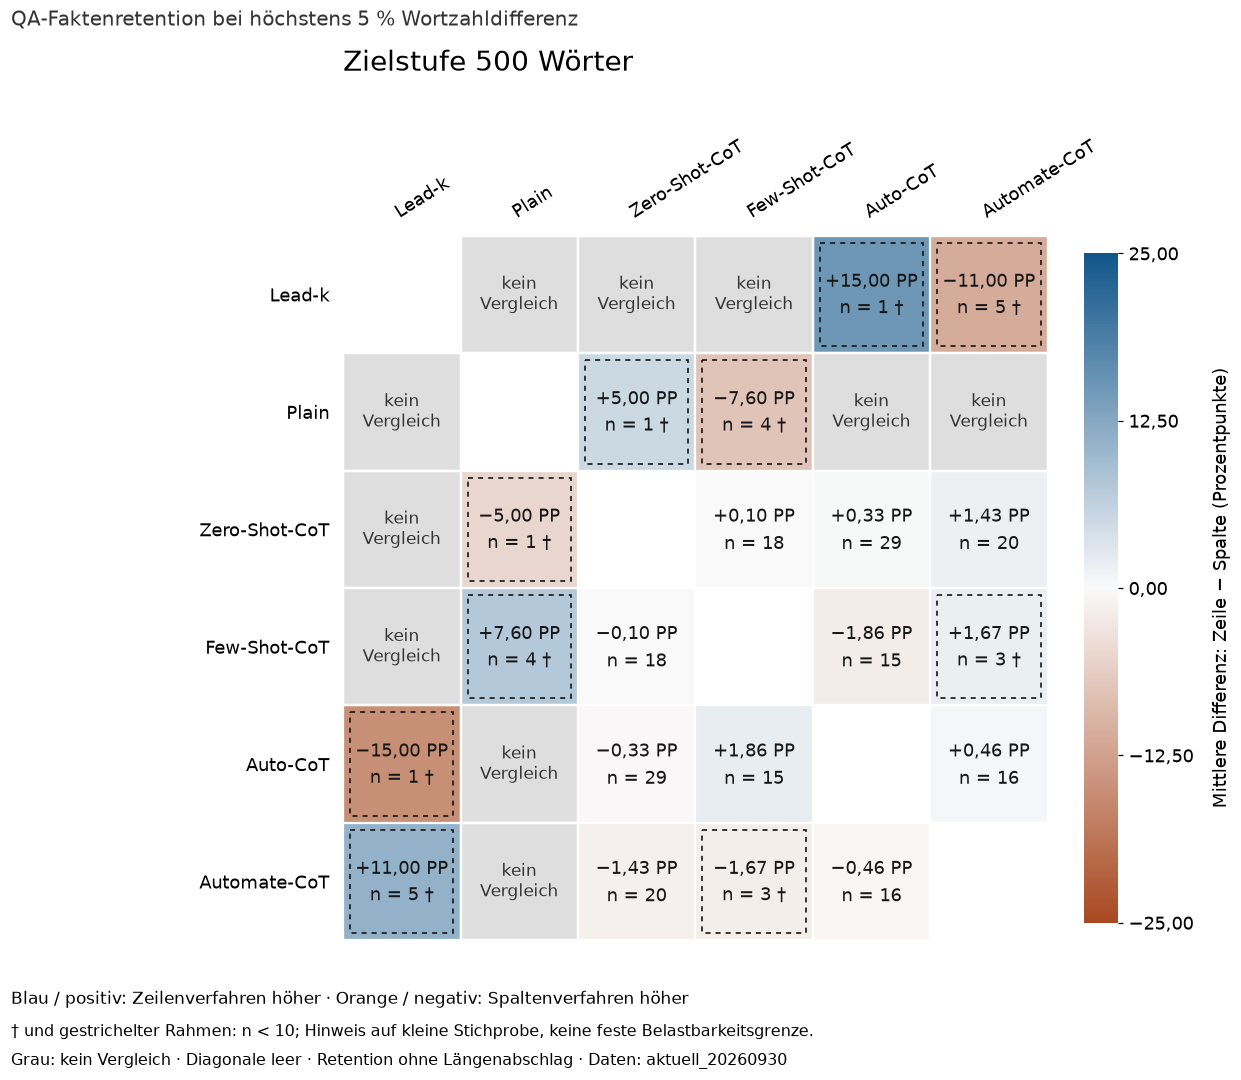

In [7]:
figure = draw_matrix(500)
display_figure(figure)
plt.close(figure)


### Begleitende Intervalltabelle: 500 Zielwörter

10.000 Bootstrap-Ziehungen vollständiger Artikelpaare. Punktweise 95-%-Perzentilintervalle, ohne Korrektur für multiple Vergleiche.

In [8]:
display(interval_table(500).style.hide(axis='index'))


Zeilenverfahren,Spaltenverfahren,ΔR (PP),n,95-%-Perzentilintervall (PP),Hinweis
Lead-k,Plain,—,0,kein Intervall (n < 2),kein Vergleich
Lead-k,Zero-Shot-CoT,—,0,kein Intervall (n < 2),kein Vergleich
Lead-k,Few-Shot-CoT,—,0,kein Intervall (n < 2),kein Vergleich
Lead-k,Auto-CoT,"+15,00",1,kein Intervall (n < 2),† kleine Stichprobe
Lead-k,Automate-CoT,"−11,00",5,"[−18,00; −4,00]",† kleine Stichprobe
Plain,Zero-Shot-CoT,"+5,00",1,kein Intervall (n < 2),† kleine Stichprobe
Plain,Few-Shot-CoT,"−7,60",4,"[−11,49; −2,50]",† kleine Stichprobe
Plain,Auto-CoT,—,0,kein Intervall (n < 2),kein Vergleich
Plain,Automate-CoT,—,0,kein Intervall (n < 2),kein Vergleich
Zero-Shot-CoT,Few-Shot-CoT,"+0,10",18,"[−4,06; +3,87]",


## Vergleichsmatrix: 300 Zielwörter

Mittlere gepaarte Differenz in Prozentpunkten und n; dieselbe Farbskala wie auf allen anderen Stufen.

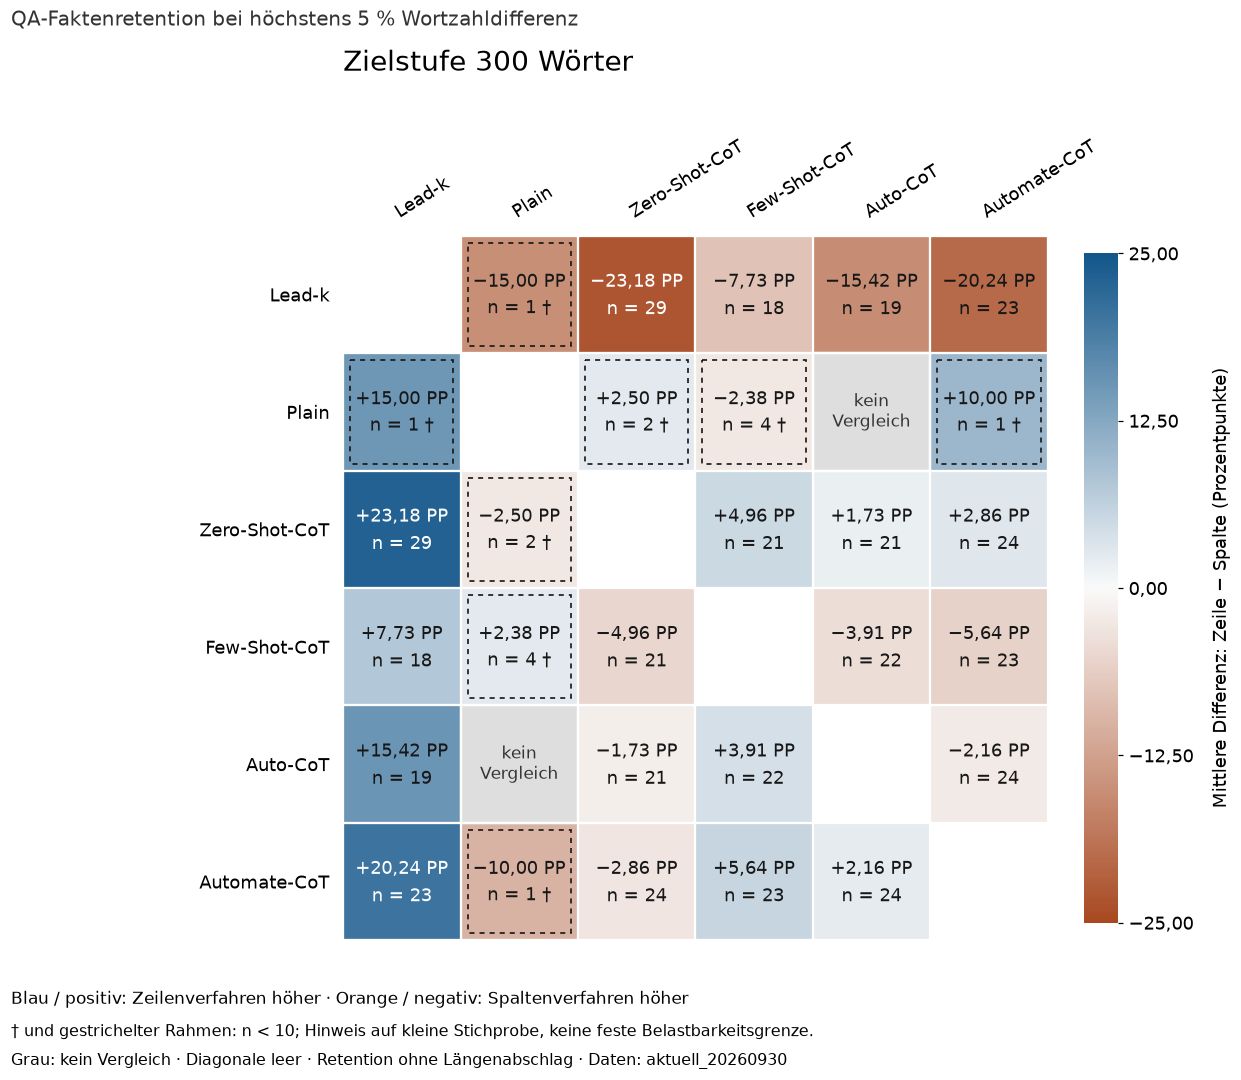

In [9]:
figure = draw_matrix(300)
display_figure(figure)
plt.close(figure)


### Begleitende Intervalltabelle: 300 Zielwörter

10.000 Bootstrap-Ziehungen vollständiger Artikelpaare. Punktweise 95-%-Perzentilintervalle, ohne Korrektur für multiple Vergleiche.

In [10]:
display(interval_table(300).style.hide(axis='index'))


Zeilenverfahren,Spaltenverfahren,ΔR (PP),n,95-%-Perzentilintervall (PP),Hinweis
Lead-k,Plain,"−15,00",1,kein Intervall (n < 2),† kleine Stichprobe
Lead-k,Zero-Shot-CoT,"−23,18",29,"[−29,38; −17,04]",
Lead-k,Few-Shot-CoT,"−7,73",18,"[−14,56; −0,91]",
Lead-k,Auto-CoT,"−15,42",19,"[−22,16; −9,20]",
Lead-k,Automate-CoT,"−20,24",23,"[−24,31; −16,36]",
Plain,Zero-Shot-CoT,"+2,50",2,"[+0,00; +5,00]",† kleine Stichprobe
Plain,Few-Shot-CoT,"−2,38",4,"[−13,16; +12,17]",† kleine Stichprobe
Plain,Auto-CoT,—,0,kein Intervall (n < 2),kein Vergleich
Plain,Automate-CoT,"+10,00",1,kein Intervall (n < 2),† kleine Stichprobe
Zero-Shot-CoT,Few-Shot-CoT,"+4,96",21,"[+0,34; +9,67]",


## Vergleichsmatrix: 150 Zielwörter

Mittlere gepaarte Differenz in Prozentpunkten und n; dieselbe Farbskala wie auf allen anderen Stufen.

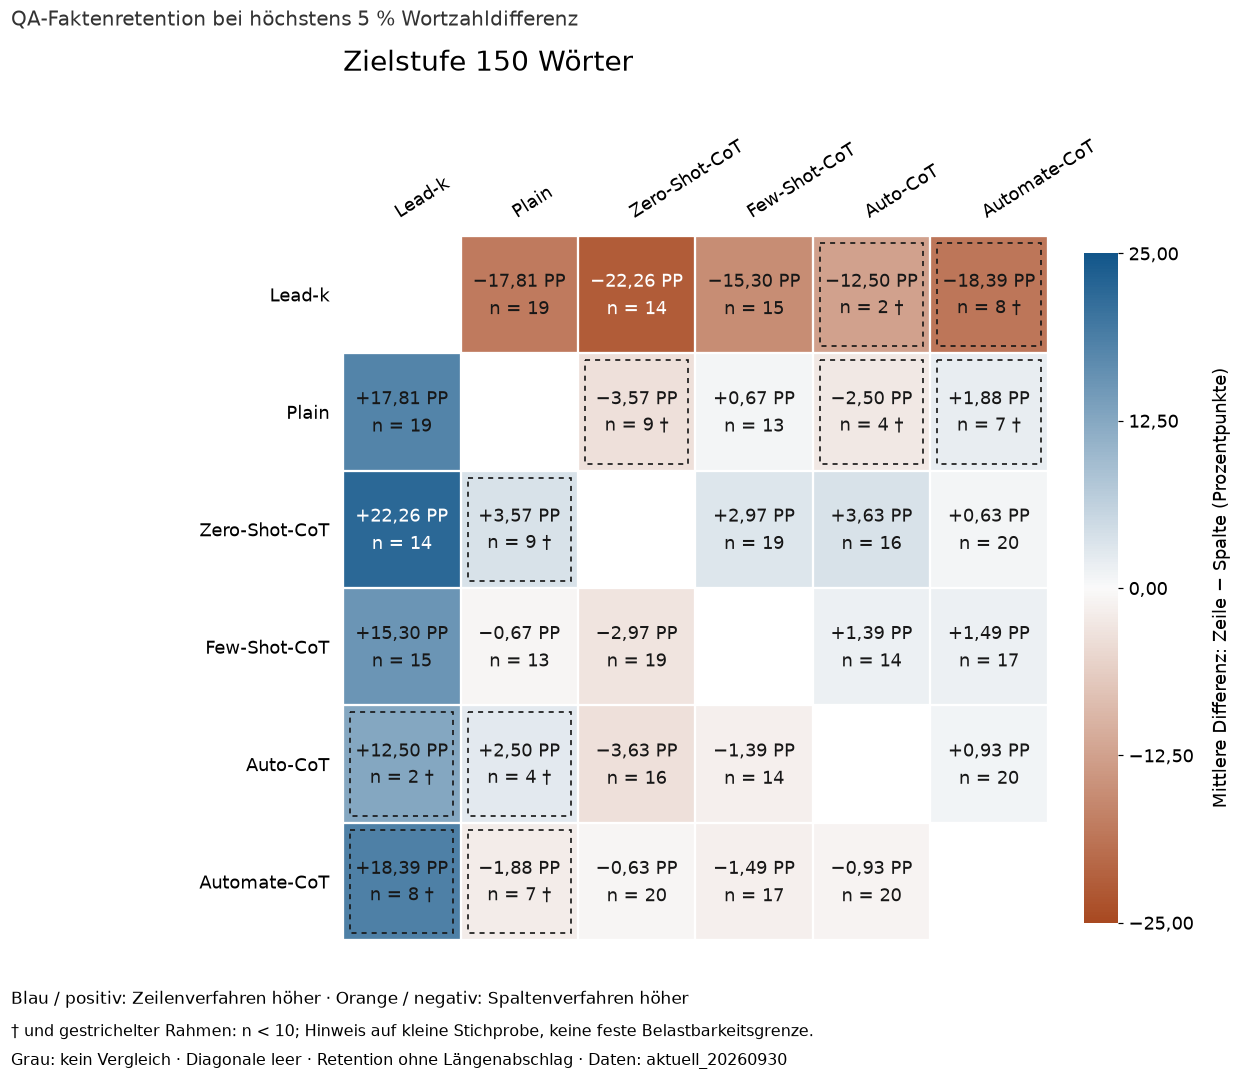

In [11]:
figure = draw_matrix(150)
display_figure(figure)
plt.close(figure)


### Begleitende Intervalltabelle: 150 Zielwörter

10.000 Bootstrap-Ziehungen vollständiger Artikelpaare. Punktweise 95-%-Perzentilintervalle, ohne Korrektur für multiple Vergleiche.

In [12]:
display(interval_table(150).style.hide(axis='index'))


Zeilenverfahren,Spaltenverfahren,ΔR (PP),n,95-%-Perzentilintervall (PP),Hinweis
Lead-k,Plain,"−17,81",19,"[−24,65; −10,44]",
Lead-k,Zero-Shot-CoT,"−22,26",14,"[−29,64; −14,64]",
Lead-k,Few-Shot-CoT,"−15,30",15,"[−24,25; −5,91]",
Lead-k,Auto-CoT,"−12,50",2,"[−30,00; +5,00]",† kleine Stichprobe
Lead-k,Automate-CoT,"−18,39",8,"[−24,38; −13,12]",† kleine Stichprobe
Plain,Zero-Shot-CoT,"−3,57",9,"[−11,35; +3,27]",† kleine Stichprobe
Plain,Few-Shot-CoT,"+0,67",13,"[−4,23; +5,47]",
Plain,Auto-CoT,"−2,50",4,"[−5,00; +0,00]",† kleine Stichprobe
Plain,Automate-CoT,"+1,88",7,"[−5,71; +10,19]",† kleine Stichprobe
Zero-Shot-CoT,Few-Shot-CoT,"+2,97",19,"[−1,55; +7,69]",


## Vergleichsmatrix: 75 Zielwörter

Mittlere gepaarte Differenz in Prozentpunkten und n; dieselbe Farbskala wie auf allen anderen Stufen.

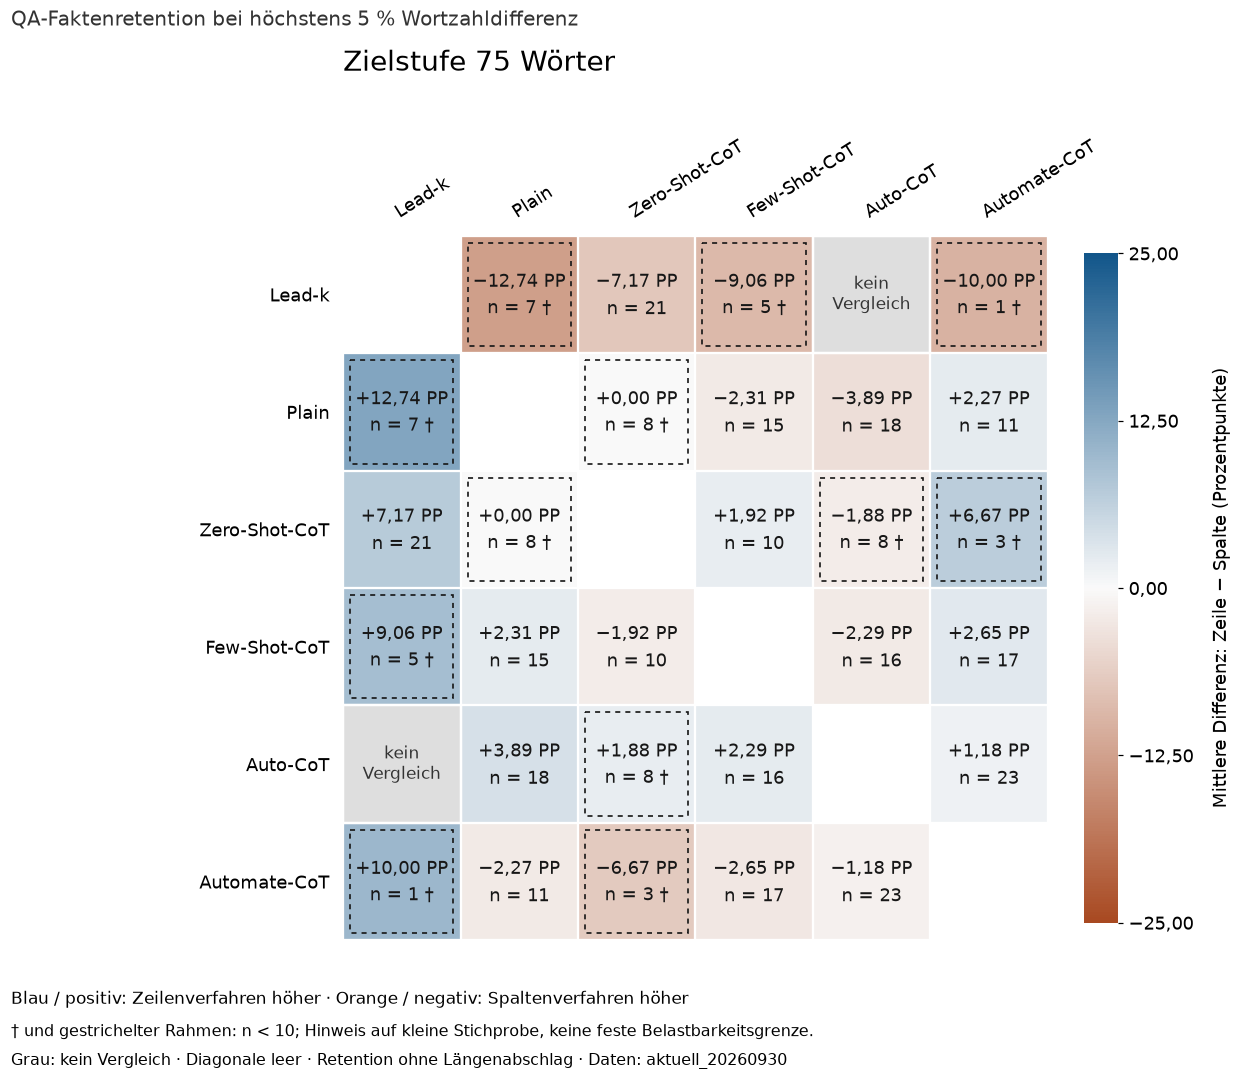

In [13]:
figure = draw_matrix(75)
display_figure(figure)
plt.close(figure)


### Begleitende Intervalltabelle: 75 Zielwörter

10.000 Bootstrap-Ziehungen vollständiger Artikelpaare. Punktweise 95-%-Perzentilintervalle, ohne Korrektur für multiple Vergleiche.

In [14]:
display(interval_table(75).style.hide(axis='index'))


Zeilenverfahren,Spaltenverfahren,ΔR (PP),n,95-%-Perzentilintervall (PP),Hinweis
Lead-k,Plain,"−12,74",7,"[−25,00; −2,52]",† kleine Stichprobe
Lead-k,Zero-Shot-CoT,"−7,17",21,"[−11,43; −2,67]",
Lead-k,Few-Shot-CoT,"−9,06",5,"[−12,12; −6,00]",† kleine Stichprobe
Lead-k,Auto-CoT,—,0,kein Intervall (n < 2),kein Vergleich
Lead-k,Automate-CoT,"−10,00",1,kein Intervall (n < 2),† kleine Stichprobe
Plain,Zero-Shot-CoT,"+0,00",8,"[−3,75; +3,75]",† kleine Stichprobe
Plain,Few-Shot-CoT,"−2,31",15,"[−6,98; +2,02]",
Plain,Auto-CoT,"−3,89",18,"[−7,78; −0,28]",
Plain,Automate-CoT,"+2,27",11,"[−4,09; +9,09]",
Zero-Shot-CoT,Few-Shot-CoT,"+1,92",10,"[−4,37; +7,71]",


## Rechenprüfungen und Exporte

Die Auswahl und die gerichteten Matrixwerte werden gegen eine zweite, artikelweise Rechnung mit exakten rationalen Retentionsquoten geprüft.

In [15]:
from fractions import Fraction
lookup_values = article_values.set_index(KEY)
for result in comparisons.itertuples(index=False):
    exact_differences, exact_ids = [], []
    for article_id in IDS:
        row = lookup_values.loc[(article_id,result.row_method,result.stage_target_words)]
        column = lookup_values.loc[(article_id,result.column_method,result.stage_target_words)]
        w_sum = int(row.W+column.W)
        if w_sum == 0 or Fraction(2*abs(int(row.W-column.W)), w_sum) > Fraction(1,20):
            continue
        if row.n_valid <= 0 or column.n_valid <= 0:
            continue
        exact_ids.append(article_id)
        exact_differences.append(100*(Fraction(int(row.n_retained),int(row.n_valid))-
                                     Fraction(int(column.n_retained),int(column.n_valid))))
    assert len(exact_ids) == result.n
    selected_audit = pair_audit[(pair_audit.stage_target_words.eq(result.stage_target_words)) &
                              pair_audit.row_method.eq(result.row_method) & pair_audit.column_method.eq(result.column_method) &
                              pair_audit.included]
    assert exact_ids == selected_audit.article_id.tolist()
    if exact_differences:
        assert abs(float(sum(exact_differences)/len(exact_differences))-result.mean_delta_pp) < 1e-12
    reverse = matrix_cells[(matrix_cells.stage_target_words.eq(result.stage_target_words)) &
                           matrix_cells.row_method.eq(result.column_method) & matrix_cells.column_method.eq(result.row_method)].iloc[0]
    assert reverse.n == result.n
    assert np.isclose(reverse.mean_delta_pp, -result.mean_delta_pp, equal_nan=True)
    assert np.isclose(reverse.ci95_low_pp, -result.ci95_high_pp, equal_nan=True)
    assert np.isclose(reverse.ci95_high_pp, -result.ci95_low_pp, equal_nan=True)
    if result.n < 2:
        assert np.isnan(result.ci95_low_pp) and np.isnan(result.ci95_high_pp)
    else:
        assert result.ci95_low_pp <= result.ci95_high_pp
        assert -100 <= result.ci95_low_pp <= 100 and -100 <= result.ci95_high_pp <= 100
assert np.allclose(matrix_cells.mean_delta_pp.dropna().clip(-COLOR_LIMIT,COLOR_LIMIT),
                   matrix_cells.mean_delta_pp.dropna())
execution_manifest = {
    "version":VERSION, "articles":len(IDS), "outputs":len(article_values), "qa_positions":len(scored),
    "selection":"same article and target; mean words > 0; 40*abs(W_row-W_column) <= W_row+W_column",
    "retention":"n_retained/n_valid; positive valid denominator; observed; no length penalty",
    "aggregation":"unweighted mean of within-article differences; delta=100*(row-column)",
    "bootstrap_draws":B, "seed":SEED, "resampling_unit":"complete selected article pair, with replacement; sample size n",
    "rng":"numpy default_rng(SeedSequence([32, target_words, row_method_index, column_method_index])); i<j",
    "interval":"pointwise percentile 95%; linear quantiles; n<2 unavailable; no multiplicity correction",
    "small_sample":"0<n<10: dagger and dashed cell border; descriptive indicator only",
    "color_limits_pp":[-COLOR_LIMIT,COLOR_LIMIT], "color_midpoint":0,
    "unique_comparisons":60, "directed_matrix_cells":120,
    "validation":{"word_counts":2400, "qa_export_matches":2400, "length_export_matches":2400,
                  "archived_retention_matches":2400, "exact_fraction_pair_comparisons":60,
                  "antisymmetric_matrix_comparisons":60},
    "python":platform.python_version(),
    "packages":{name:importlib.metadata.version(name) for name in ["numpy","pandas","matplotlib","nbformat","nbclient","nbconvert","ipykernel"]},
    "sources":sources,
}
(OUT/"execution_manifest.json").write_text(json.dumps(execution_manifest,indent=2,ensure_ascii=False),encoding="utf-8")
with (OUT/"intervalltabellen.md").open("w",encoding="utf-8") as stream:
    stream.write("# Begleitende 95-%-Bootstrap-Perzentilintervalle\n\n"
                 "10.000 Ziehungen vollständiger Artikelpaare, Seed 32. ΔR = Zeile − Spalte in Prozentpunkten. "
                 "Punktweise Intervalle, keine Korrektur für multiple Vergleiche. "
                 "†: n < 10; Hinweis auf kleine Stichprobe, keine feste Belastbarkeitsgrenze. "
                 "Für n < 2 kein Intervall. Datenstand: aktuell_20260930.\n\n")
    for target in STAGES:
        table = interval_table(target)
        stream.write(f"## {target} Zielwörter\n\n")
        stream.write("| "+" | ".join(table.columns)+" |\n")
        stream.write("| "+" | ".join(["---"]*len(table.columns))+" |\n")
        for row in table.itertuples(index=False,name=None):
            stream.write("| "+" | ".join(str(value) for value in row)+" |\n")
        stream.write("\n")
display(Markdown("**Alle Rechenprüfungen bestanden.** Vier Matrizen (PNG, SVG, PDF), vier Intervalltabellen, "
                 "ungerundete Ergebnisse, vollständiger Paarbildungs-Audit, Bootstrap-Verteilungen und Quellenhashes sind gespeichert."))


**Alle Rechenprüfungen bestanden.** Vier Matrizen (PNG, SVG, PDF), vier Intervalltabellen, ungerundete Ergebnisse, vollständiger Paarbildungs-Audit, Bootstrap-Verteilungen und Quellenhashes sind gespeichert.